In [ ]:
# Trabalho teórico/computacional - Cadeias de Markov

In [2]:
#importando bibliotecas necessárias
import numpy as np

In [ ]:
#Lista de tarefas Q2, i e ii

In [3]:
#matriz de probabilidade de transição de 1 passo
P = np.array([
    [0.7, 0.28, 0.02],
    [0.35, 0.45, 0.2],
    [0.1, 0.4, 0.5]
])

#definindo N
N = np.array([10,20,50,100,200], dtype=int)

# realizando a operação pela propriedade de exponencial
for i in N:
    P_N = np.linalg.matrix_power(P,i)
    print("resultado para ",i)
    print(P_N)

[[0.7  0.28 0.02]
 [0.35 0.45 0.2 ]
 [0.1  0.4  0.5 ]]
resultado para  10
[[0.47640788 0.36077959 0.16281253]
 [0.47526051 0.36106138 0.1636781 ]
 [0.47405832 0.36135664 0.16458504]]
resultado para  20
[[0.4756114  0.36097521 0.1634134 ]
 [0.47560904 0.36097579 0.16341518]
 [0.47560657 0.36097639 0.16341704]]
resultado para  50
[[0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]]
resultado para  100
[[0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]]
resultado para  200
[[0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]
 [0.47560976 0.36097561 0.16341463]]


In [ ]:
#Lista de tarefas Q2, iii 

In [11]:
#definindo os estados iniciais na ordem N, P, E como vetores

estados_iniciais = {
    "Iniciando em N [1, 0, 0]": np.array([1.0, 0.0, 0.0]),
    "Iniciando em P [0, 1, 0]": np.array([0.0, 1.0, 0.0]),
    "Iniciando em E [0, 0, 1]": np.array([0.0, 0.0, 1.0])
}

# para cada nome de vetor e vetor
for nome, pi_0 in estados_iniciais.items():
    print(f"Cenario: {nome}")
    for n in N:
        # multiplicando a matriz de transição com n passos pelo vetor do estado inicial
        pi_n = pi_0 @ np.linalg.matrix_power(P, n)
        print(f"  n = {n:3d} | Probabilidade de cada estado [N, P, E]: {pi_n}")

Cenario: Iniciando em N [1, 0, 0]
  n =  10 | Probabilidade de cada estado [N, P, E]: [0.47640788 0.36077959 0.16281253]
  n =  20 | Probabilidade de cada estado [N, P, E]: [0.4756114  0.36097521 0.1634134 ]
  n =  50 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
  n = 100 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
  n = 200 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
Cenario: Iniciando em P [0, 1, 0]
  n =  10 | Probabilidade de cada estado [N, P, E]: [0.47526051 0.36106138 0.1636781 ]
  n =  20 | Probabilidade de cada estado [N, P, E]: [0.47560904 0.36097579 0.16341518]
  n =  50 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
  n = 100 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
  n = 200 | Probabilidade de cada estado [N, P, E]: [0.47560976 0.36097561 0.16341463]
Cenario: Iniciando em E [0, 0, 1]
  n =  10 | Probabilidade de

In [ ]:
#Lista de tarefas Q2, iv

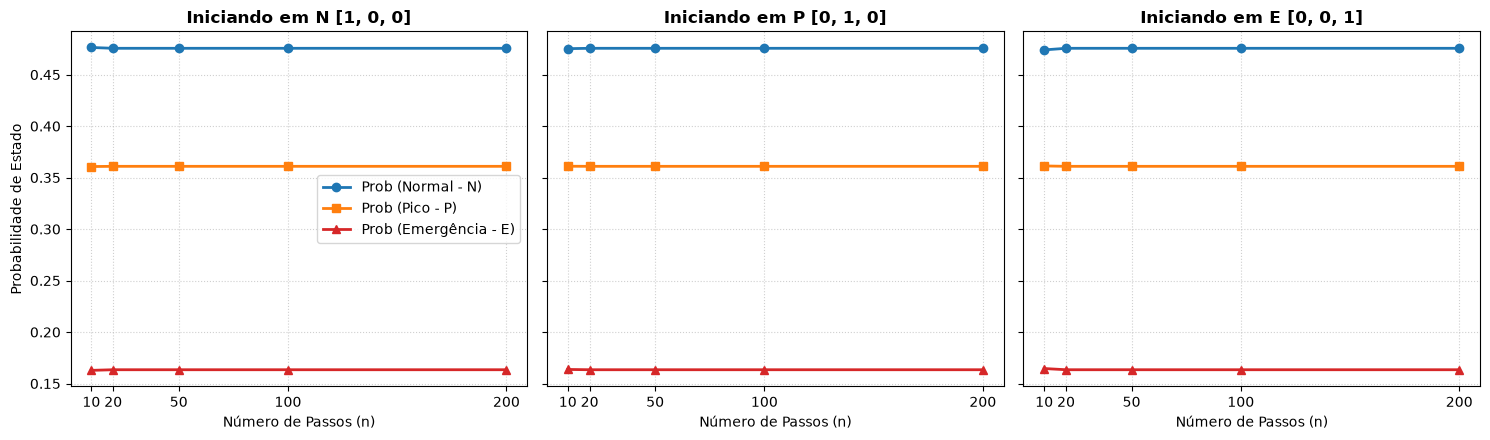

In [15]:
# Criando 3 subplots lado a lado
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
# para cada estado inicial, e o seu respectivo vetor
for ax, (titulo, pi_0) in zip(axes, estados_iniciais.items()):
    probs_N, probs_P, probs_E = [], [], []
    # para cada valor de N
    for n in N:
        #calculo da matriz de transição de n passos com cada vetor de estado inicial
        pi_n = pi_0 @ np.linalg.matrix_power(P, n)
        # cada vetor de resultado é armazenado
        probs_N.append(pi_n[0])
        probs_P.append(pi_n[1])
        probs_E.append(pi_n[2])
    
    # cada linha de probabilidade de cada estado ao longo de n
    ax.plot(N, probs_N, 'o-', label='Prob (Normal - N)', color='#1f77b4', linewidth=2)
    ax.plot(N, probs_P, 's-', label='Prob (Pico - P)', color='#ff7f0e', linewidth=2)
    ax.plot(N, probs_E, '^-', label='Prob (Emergência - E)', color='#d62728', linewidth=2)

    # configurações do plot
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Número de Passos (n)')
    ax.set_xticks(N)
    ax.grid(True, linestyle=':', alpha=0.6)
    
    if ax == axes[0]:
        ax.set_ylabel('Probabilidade de Estado')
        ax.legend()
        
plt.tight_layout()
plt.show()